In [6]:
import pandas as pd

In [7]:
columns = [
    "duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
    "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
    "root_shell","su_attempted","num_root","num_file_creations","num_shells",
    "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
    "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
    "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
    "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
    "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
    "label","difficulty"
]

In [ ]:
train_df = pd.read_csv(r"C:\Users\Deepak\OneDrive\Desktop\ML based IDS\Dataset\KDDTrain+.txt", names=columns)
test_df = pd.read_csv(r"C:\Users\Deepak\OneDrive\Desktop\ML based IDS\Dataset\KDDTest+.txt", names=columns)

In [8]:
print(train_df.shape, test_df.shape)
train_df.head()

(125973, 43) (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [9]:
train_df["binary_label"] = train_df["label"].apply(lambda x: "normal" if x == "normal" else "attack")
test_df["binary_label"] = test_df["label"].apply(lambda x: "normal" if x == "normal" else "attack")

In [10]:
train_df["binary_label"].value_counts()

binary_label
normal    67343
attack    58630
Name: count, dtype: int64

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

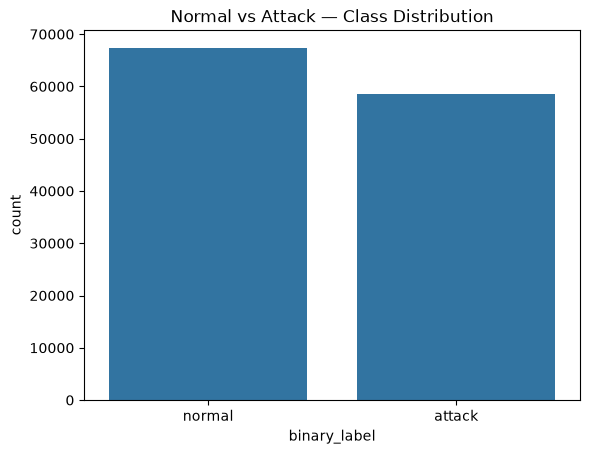

In [12]:
sns.countplot(x="binary_label", data=train_df)
plt.title("Normal vs Attack — Class Distribution")
plt.show()

In [13]:
print(train_df.isnull().sum().sum())

0


In [14]:
for col in ["protocol_type", "service", "flag"]:
    print(col, train_df[col].nunique(), "unique values")

protocol_type 3 unique values
service 70 unique values
flag 11 unique values


In [16]:
from sklearn.preprocessing import LabelEncoder
import numpy as np

categorical_cols = ["protocol_type", "service", "flag"]
encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    train_df[col] = le.fit_transform(train_df[col])

    # Handle unseen categories in test set
    test_df[col] = test_df[col].map(lambda s: s if s in le.classes_ else "unseen")
    le.classes_ = np.array(list(le.classes_) + ["unseen"])  # <-- fixed: back to np.array
    test_df[col] = le.transform(test_df[col])

    encoders[col] = le

In [17]:
train_df["target"] = train_df["binary_label"].map({"normal": 0, "attack": 1})
test_df["target"] = test_df["binary_label"].map({"normal": 0, "attack": 1})

In [18]:
from sklearn.preprocessing import StandardScaler

drop_cols = ["label", "binary_label", "difficulty", "target"]
X_train = train_df.drop(columns=drop_cols)
y_train = train_df["target"]
X_test = test_df.drop(columns=drop_cols)
y_test = test_df["target"]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [22]:
print(X_train_scaled.shape, X_test_scaled.shape) #sanity check
print(y_train.value_counts())

(125973, 41) (22544, 41)
target
0    67343
1    58630
Name: count, dtype: int64


In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)
lr_preds = lr.predict(X_test_scaled)

print(classification_report(y_test, lr_preds))

              precision    recall  f1-score   support

           0       0.57      0.99      0.72      9711
           1       0.98      0.44      0.60     12833

    accuracy                           0.67     22544
   macro avg       0.77      0.71      0.66     22544
weighted avg       0.80      0.67      0.65     22544



In [24]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train)
rf_preds = rf.predict(X_test_scaled)

print(classification_report(y_test, rf_preds))

              precision    recall  f1-score   support

           0       0.65      0.97      0.78      9711
           1       0.97      0.60      0.74     12833

    accuracy                           0.76     22544
   macro avg       0.81      0.79      0.76     22544
weighted avg       0.83      0.76      0.76     22544



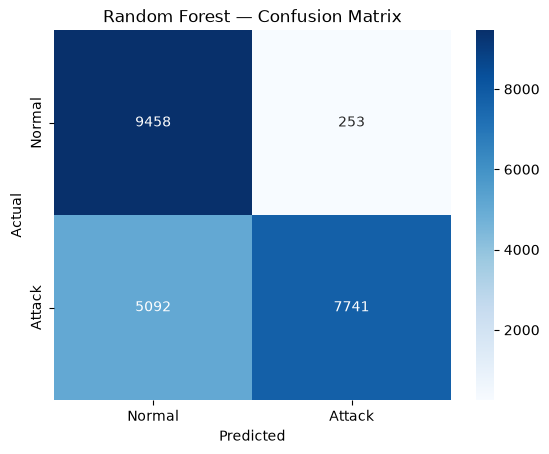

In [25]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, rf_preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal","Attack"], yticklabels=["Normal","Attack"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest — Confusion Matrix")
plt.show()

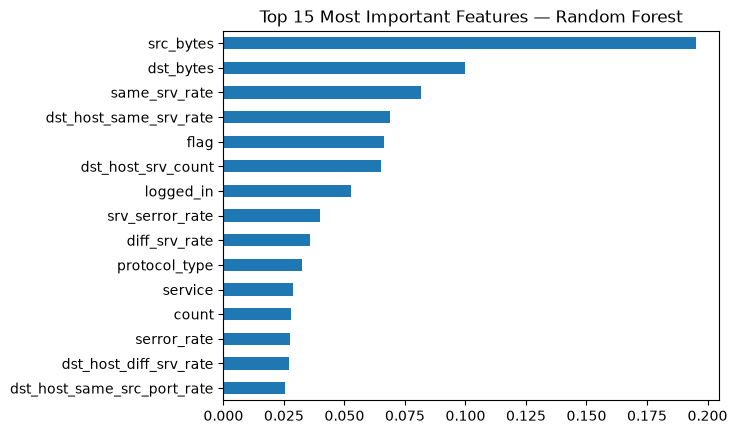

In [26]:
#feature importance

importances = pd.Series(rf.feature_importances_, index=X_train.columns) 
importances.sort_values(ascending=False).head(15).plot(kind="barh")
plt.title("Top 15 Most Important Features — Random Forest")
plt.gca().invert_yaxis()
plt.show()

In [4]:
attack_map = {
    'normal': 'normal',
    # DoS
    'back':'dos','land':'dos','neptune':'dos','pod':'dos','smurf':'dos','teardrop':'dos',
    'apache2':'dos','udpstorm':'dos','processtable':'dos','worm':'dos','mailbomb':'dos',
    # Probe
    'satan':'probe','ipsweep':'probe','nmap':'probe','portsweep':'probe','mscan':'probe','saint':'probe',
    # R2L
    'guess_passwd':'r2l','ftp_write':'r2l','imap':'r2l','phf':'r2l','multihop':'r2l',
    'warezmaster':'r2l','warezclient':'r2l','spy':'r2l','xlock':'r2l','xsnoop':'r2l',
    'snmpguess':'r2l','snmpgetattack':'r2l','httptunnel':'r2l','sendmail':'r2l','named':'r2l',
    # U2R
    'buffer_overflow':'u2r','loadmodule':'u2r','rootkit':'u2r','perl':'u2r',
    'sqlattack':'u2r','xterm':'u2r','ps':'u2r'
}

train_df["category"] = train_df["label"].map(attack_map)
test_df["category"] = test_df["label"].map(attack_map)

# Check: both should print 0
print("Unmapped rows:", train_df["category"].isnull().sum(), test_df["category"].isnull().sum())
print(train_df["category"].value_counts())
print(test_df["category"].value_counts())

# Train 5-class Random Forest
y_train_multi = train_df["category"]
y_test_multi = test_df["category"]

rf_multi = RandomForestClassifier(n_estimators=100, random_state=42)
rf_multi.fit(X_train_scaled, y_train_multi)
rf_multi_preds = rf_multi.predict(X_test_scaled)

print(classification_report(y_test_multi, rf_multi_preds))

# Confusion matrix
labels_order = ["normal", "dos", "probe", "r2l", "u2r"]
cm_multi = confusion_matrix(y_test_multi, rf_multi_preds, labels=labels_order)

sns.heatmap(cm_multi, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels_order, yticklabels=labels_order)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Multi-Class Confusion Matrix")
plt.show()

Unmapped rows: 0 0
category
normal    67343
dos       45927
probe     11656
r2l         995
u2r          52
Name: count, dtype: int64
category
normal    9711
dos       7460
r2l       2885
probe     2421
u2r         67
Name: count, dtype: int64
              precision    recall  f1-score   support

         dos       0.96      0.77      0.85      7460
      normal       0.65      0.97      0.78      9711
       probe       0.87      0.67      0.76      2421
         r2l       0.98      0.04      0.08      2885
         u2r       0.50      0.03      0.06        67

    accuracy                           0.75     22544
   macro avg       0.79      0.50      0.51     22544
weighted avg       0.82      0.75      0.71     22544



<Figure size 640x480 with 2 Axes>

In [5]:
#improve rare-class detection

rf_balanced = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")
rf_balanced.fit(X_train_scaled, y_train_multi)
rf_balanced_preds = rf_balanced.predict(X_test_scaled)

print(classification_report(y_test_multi, rf_balanced_preds))

              precision    recall  f1-score   support

         dos       0.96      0.80      0.87      7460
      normal       0.64      0.97      0.78      9711
       probe       0.86      0.60      0.70      2421
         r2l       0.71      0.00      0.00      2885
         u2r       0.50      0.03      0.06        67

    accuracy                           0.75     22544
   macro avg       0.74      0.48      0.48     22544
weighted avg       0.78      0.75      0.70     22544



In [8]:
r2l_test = test_df[test_df["category"] == "r2l"].copy()
r2l_test["seen_in_train"] = r2l_test["label"].isin(set(train_df["label"]))

print(r2l_test["seen_in_train"].value_counts())
print(r2l_test["label"].value_counts().head(10))

seen_in_train
True     2199
False     686
Name: count, dtype: int64
label
guess_passwd     1231
warezmaster       944
snmpguess         331
snmpgetattack     178
httptunnel        133
multihop           18
named              17
sendmail           14
xlock               9
xsnoop              4
Name: count, dtype: int64


In [9]:
print(train_df[train_df["category"] == "r2l"]["label"].value_counts())

label
warezclient     890
guess_passwd     53
warezmaster      20
imap             11
ftp_write         8
multihop          7
phf               4
spy               2
Name: count, dtype: int64


In [10]:
r2l_mask = (test_df["category"] == "r2l").values
r2l_test = test_df[r2l_mask].copy()
r2l_test["pred"] = rf_multi_preds[r2l_mask]

recall_by_type = r2l_test.groupby("label")["pred"].apply(lambda s: (s == "r2l").mean())
counts = r2l_test["label"].value_counts()
print(pd.DataFrame({"count": counts, "recall": recall_by_type}).sort_values("count", ascending=False).head(10))

               count    recall
label                         
guess_passwd    1231  0.000000
warezmaster      944  0.132415
snmpguess        331  0.000000
snmpgetattack    178  0.000000
httptunnel       133  0.000000
multihop          18  0.000000
named             17  0.000000
sendmail          14  0.000000
xlock              9  0.000000
xsnoop             4  0.000000
